<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Football League Data](https://github.com/Query-farm/vgi-nfl)

NFL scores, standings, box scores, play-by-play, and player statistics as SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nfl/blob/main/notebooks/04_follow_one_game_across_statistical_ledgers.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nfl/blob/main/notebooks/README.md)


## Follow one game across statistical ledgers

A scoreboard, scoring ledger, drive report and player box score describe the same game at different grains. Can we reconcile their keys and totals without treating every event as an official offensive play or mixing gross player yards with net team offense?

**Real public responses, recorded independently on 2026-11-15 UTC.** Default replay serves complete unchanged response bodies through the released worker. The [provenance manifest](recordings/provenance.json) keeps acquisition times, URLs and hashes. These are historical observations, not synthetic data or an atomic snapshot. All analytical transformations stay in visible SQL.

### Choose one local rule

`MIN_SCRIMMAGE_YARDS` changes only the final player display, using rushing plus receiving yards in the fixed 2025 season opener: Dallas at Philadelphia, ESPN event `401772510`. The scoring timeline, nine source relations and team reconciliations stay fixed. `150` is an empty-selection boundary.

In [1]:
DATA_MODE = "replay"
MIN_SCRIMMAGE_YARDS = 25  # Integer 0–150; experiment: 75

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.54":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.54"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nfl")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nfl_examples import NFLExample

if type(MIN_SCRIMMAGE_YARDS) is not int or not 0 <= MIN_SCRIMMAGE_YARDS <= 150:
    raise ValueError("MIN_SCRIMMAGE_YARDS must be an integer from 0 to 150")
source = NFLExample(DATA_MODE, "game")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public ESPN responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public ESPN responses · independent reads"
) + " · worker v0.2.0"

### Attach the public release

The short tag command owns dependencies in a separate Python 3.13 worker process. Shared setup starts UTC with empty temporary SQL secrets and persistence disabled. The companion verifies hashes and permits only this scenario's exact requests on loopback; all other upstream roots also point to the rejecting loopback server. Live mode clears inherited root overrides, uses the public endpoints and never falls back to recordings. Restart and run all in a fresh kernel after changing a parameter.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nfl' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nfl@v0.2.0 vgi-nfl');

,Success


### Resolve the same event across broader collections

The week scoreboard contains the league’s games; Philadelphia’s season schedule has a different population. Their intersection on the **ESPN game ID** resolves the opener, not a join on team names. The current team directory supplies the full labels for the historical team IDs; it is not a historical roster.

The six detail functions share one cached ESPN summary response. Materialize every call once: nine SQL objects require only four response bodies in replay. These are independently captured, complete public ESPN responses, with no generated scores. ESPN’s endpoints are unofficial and subject to its terms; this is a bounded historical example, not an affiliated feed.

In [5]:
%%sql
CREATE TABLE week_games AS SELECT * FROM nfl.main.scoreboard(2025,1);
CREATE TABLE club_games AS SELECT * FROM nfl.main.team_schedule('PHI',season:=2025);
CREATE TABLE team_directory AS SELECT * FROM nfl.main.teams;
CREATE TABLE summary AS SELECT * FROM nfl.main.game_summary('401772510');
CREATE TABLE team_box AS SELECT * FROM nfl.main.box_score_team('401772510');
CREATE TABLE player_box AS SELECT * FROM nfl.main.box_score_player('401772510');
CREATE TABLE drive_rows AS SELECT * FROM nfl.main.drives('401772510');
CREATE TABLE score_rows AS SELECT * FROM nfl.main.scoring_plays('401772510');
CREATE TABLE event_rows AS SELECT * FROM nfl.main.play_by_play_game('401772510');
CREATE TABLE resolved_game AS
SELECT w.game_id,w.home_score,w.away_score,w.home_team_id,w.away_team_id,
 c.home_score AS club_home_score,c.away_score AS club_away_score,
 s.home_score AS summary_home_score,s.away_score AS summary_away_score,
 h.team_name AS home_name,a.team_name AS away_name
FROM week_games w JOIN club_games c USING(game_id) JOIN summary s USING(game_id)
JOIN team_directory h ON h.team_id=w.home_team_id
JOIN team_directory a ON a.team_id=w.away_team_id;

,Count


In [6]:
%%sql source_scope <<
SELECT 'Week scoreboard' AS population,count(*) AS rows FROM week_games
UNION ALL SELECT 'Philadelphia regular-season schedule',count(*) FROM club_games
UNION ALL SELECT 'Current team directory',count(*) FROM team_directory
UNION ALL SELECT 'Resolved historical game',count(*) FROM resolved_game
UNION ALL SELECT 'Drive rows',count(*) FROM drive_rows
UNION ALL SELECT 'Play-by-play event rows',count(*) FROM event_rows
UNION ALL SELECT 'Player box rows',count(*) FROM player_box ORDER BY population;

In [7]:
display(source_scope)
prose(
    "The collections remain separate until the explicit event-ID join. The team directory labels those IDs; its current publication time does not change the historical game scope. A player box row may contain several statistical categories, while a play-by-play row may be a kick, timeout, penalty or other event."
)

,population,rows
0,Current team directory,32
1,Drive rows,16
2,Philadelphia regular-season schedule,17
3,Play-by-play event rows,169
4,Player box rows,58
5,Resolved historical game,1
6,Week scoreboard,16


The collections remain separate until the explicit event-ID join. The team directory labels those IDs; its current publication time does not change the historical game scope. A player box row may contain several statistical categories, while a play-by-play row may be a kick, timeout, penalty or other event.

### Match scoring events to plays and drives

Join the scoring ledger to play-by-play on `play_id`, then to drives on the returned drive number. This tests identity and order before plotting. In this acquisition, scoring-play scores already include the completed scoring sequence; do not add extra-point events again. The final ledger scores and quarter totals must agree with the summary.

Convert period/clock into **elapsed regulation minutes** for this four-quarter game. The step line represents the recorded score between scoring sequences, not ball possession or win probability.

In [8]:
%%sql timeline <<
SELECT s.play_id,s.period,s.clock,s.team_abbreviation,s.scoring_type,
 s.away_score,s.home_score,p.sequence,p.drive_number,p.scoring_play,
 p.away_score AS event_away_score,p.home_score AS event_home_score,
 d.team_id AS drive_team_id,s.team_id AS scoring_team_id,d.result AS drive_result,d.is_score,
 ((s.period-1)*900+900-split_part(s.clock,':',1)::INTEGER*60-split_part(s.clock,':',2)::INTEGER)/60.0 AS elapsed_minutes
FROM score_rows s LEFT JOIN event_rows p USING(play_id)
LEFT JOIN drive_rows d ON d.drive_number=p.drive_number
ORDER BY p.sequence;

In [9]:
%%sql drive_audit <<
WITH d AS (SELECT team_id,count(*) AS drives,sum(plays) AS drive_reported_plays,
 sum(yards) AS drive_reported_yards,sum(duration_seconds) AS drive_seconds FROM drive_rows GROUP BY team_id),
 e AS (SELECT offense_team_id AS team_id,count(*) AS event_rows FROM event_rows GROUP BY offense_team_id)
SELECT t.team_id,t.team_abbreviation,t.total_drives AS official_drives,d.drives,
 t.total_plays AS official_offensive_plays,d.drive_reported_plays,e.event_rows,
 t.total_yards AS net_offense_yards,d.drive_reported_yards,
 t.possession_seconds,d.drive_seconds
FROM team_box t LEFT JOIN d USING(team_id) LEFT JOIN e USING(team_id) ORDER BY team_abbreviation;

,period,clock,team_abbreviation,away_score,home_score,drive_number,drive_result
0,1,11:49,DAL,7,0,1,Touchdown
1,1,5:55,PHI,7,7,2,Touchdown
2,2,14:56,DAL,14,7,3,Touchdown
3,2,6:46,PHI,14,14,4,Touchdown
4,2,2:34,DAL,17,14,5,Field Goal
5,2,0:51,PHI,17,21,6,Touchdown
6,2,0:00,DAL,20,21,7,Field Goal
7,3,8:30,PHI,20,24,8,Field Goal


,team_id,team_abbreviation,official_drives,drives,official_offensive_plays,drive_reported_plays,event_rows,net_offense_yards,drive_reported_yards,possession_seconds,drive_seconds
0,6,DAL,8,8,56,58.0,84,307,367.0,1508,1508.0
1,21,PHI,8,8,62,63.0,85,302,302.0,2092,2092.0


**8 scoring sequences** join uniquely to plays and scoring drives. The final score is **Dallas Cowboys 20 – Philadelphia Eagles 24**. Drive counts and possession seconds reconcile, but the drive-reported play counts and all event counts are visibly different from official offensive plays. We retain those differences rather than summing unlike events into a replacement box score.

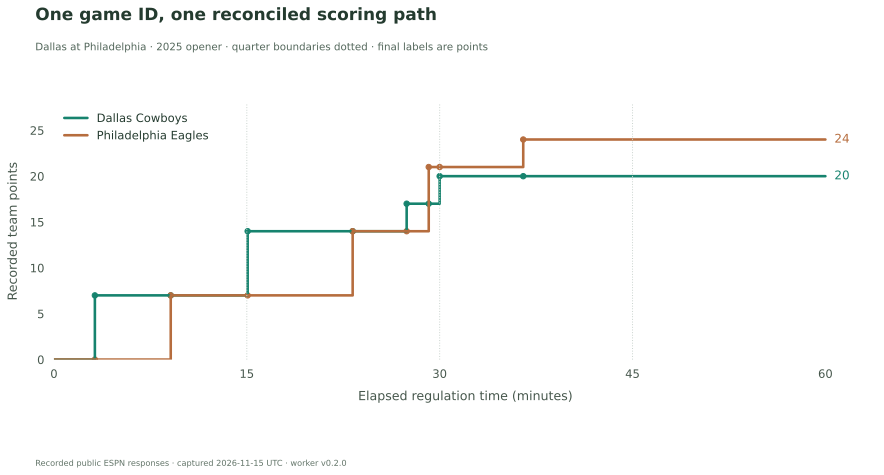

In [10]:
display(
    timeline[
        ["period", "clock", "team_abbreviation", "away_score", "home_score", "drive_number", "drive_result"]
    ]
)
display(drive_audit)
game = con.execute("SELECT * FROM resolved_game").df().iloc[0]
prose(
    f"**{len(timeline)} scoring sequences** join uniquely to plays and scoring drives. The final score is **{game.away_name} {int(game.away_score)} – {game.home_name} {int(game.home_score)}**. Drive counts and possession seconds reconcile, but the drive-reported play counts and all event counts are visibly different from official offensive plays. We retain those differences rather than summing unlike events into a replacement box score."
)
fig, ax = plt.subplots(figsize=(13, 7))
x = [0, *timeline.elapsed_minutes.tolist(), 60]
for column, label, color in [
    ("away_score", game.away_name, "#16836e"),
    ("home_score", game.home_name, "#b66d3e"),
]:
    values = [0, *timeline[column].tolist(), int(timeline[column].iloc[-1])]
    ax.step(x, values, where="post", label=label, color=color, linewidth=2.6)
    ax.scatter(timeline.elapsed_minutes, timeline[column], color=color, s=30)
    ax.text(60.7, values[-1], str(values[-1]), va="center", color=color, fontsize=12)
for minute in [15, 30, 45]:
    ax.axvline(minute, color="#cbd4cf", linestyle=":", linewidth=1)
ax.set_xlim(0, 64)
ax.set_ylim(0, 28)
ax.set_xticks([0, 15, 30, 45, 60])
ax.set_xlabel("Elapsed regulation time (minutes)")
ax.set_ylabel("Recorded team points")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.legend(frameon=False, loc="upper left")
finish(
    fig,
    title="One game ID, one reconciled scoring path",
    subtitle="Dallas at Philadelphia · 2025 opener · quarter boundaries dotted · final labels are points",
    source=SOURCE,
    name="game-scoring-ledger",
)

### Gross player scrimmage yards are not net team offense

Sum rushing plus receiving yards across the player box. A missing category for a player who did not record it contributes zero **only for this cross-category sum**; other missing fields retain their meaning. Receiving yards are the gross passing component, while team passing yards are net of sack losses. Do not add quarterback passing yards again to player receiving yards.

First reconcile gross passing, rushing and sack losses. Then use **gross player scrimmage yards** as the denominator for a contribution share. A team-net-offense denominator can make all player shares sum above 100%, so it is displayed only as a diagnostic. The display threshold hides small contributions without renormalizing the remaining players.

In [11]:
%%sql
CREATE TABLE player_yards AS
SELECT team_id,team_abbreviation,athlete_id,athlete_name,
 coalesce(rush_yards,0)+coalesce(receiving_yards,0) AS scrimmage_yards
FROM player_box;
CREATE TABLE gross_by_team AS
SELECT team_id,sum(scrimmage_yards) AS gross_scrimmage_yards FROM player_yards GROUP BY team_id;
CREATE TABLE player_display AS
SELECT p.*,g.gross_scrimmage_yards,t.total_yards AS net_offense_yards,
 100.0*p.scrimmage_yards/nullif(g.gross_scrimmage_yards,0) AS pct_gross_scrimmage
FROM player_yards p JOIN gross_by_team g USING(team_id) JOIN team_box t USING(team_id)
WHERE p.scrimmage_yards>0 AND p.scrimmage_yards>={{MIN_SCRIMMAGE_YARDS}};

,Count


In [12]:
%%sql yard_audit <<
WITH p AS (SELECT team_id,sum(coalesce(pass_yards,0)) AS player_gross_pass,
 sum(coalesce(receiving_yards,0)) AS player_receiving,
 sum(coalesce(rush_yards,0)) AS player_rushing,
 sum(coalesce(sack_yards_lost,0)) AS player_sack_losses FROM player_box GROUP BY team_id)
SELECT t.team_abbreviation,t.team_id,t.total_yards AS net_offense_yards,
 t.passing_yards AS net_passing_yards,t.rushing_yards,t.sack_yards_lost,
 p.*,g.gross_scrimmage_yards,
 100.0*g.gross_scrimmage_yards/t.total_yards AS all_players_pct_if_net_denominator
FROM team_box t JOIN p USING(team_id) JOIN gross_by_team g USING(team_id) ORDER BY t.team_abbreviation;

In [13]:
%%sql selected_players <<
SELECT * FROM player_display ORDER BY pct_gross_scrimmage DESC,athlete_id;

,team_abbreviation,team_id,net_offense_yards,net_passing_yards,rushing_yards,sack_yards_lost,team_id_1,player_gross_pass,player_receiving,player_rushing,player_sack_losses,gross_scrimmage_yards,all_players_pct_if_net_denominator
0,DAL,6,307,188,119,0,6,188.0,188.0,119.0,0.0,307.0,100.000000
1,PHI,21,302,144,158,8,21,152.0,152.0,158.0,8.0,310.0,102.649007


,team_id,team_abbreviation,athlete_id,athlete_name,scrimmage_yards,gross_scrimmage_yards,net_offense_yards,pct_gross_scrimmage
0,6,DAL,4241389,CeeDee Lamb,110,307.0,307,35.830619
1,21,PHI,3929630,Saquon Barkley,84,310.0,302,27.096774
2,6,DAL,4361579,Javonte Williams,64,307.0,307,20.846906
3,21,PHI,4040715,Jalen Hurts,62,310.0,302,20.000000
4,21,PHI,4361409,Jahan Dotson,59,310.0,302,19.032258
5,6,DAL,4045163,Miles Sanders,50,307.0,307,16.286645
6,21,PHI,3121023,Dallas Goedert,44,310.0,302,14.193548
7,6,DAL,4426354,George Pickens,30,307.0,307,9.771987
8,6,DAL,3676833,KaVontae Turpin,27,307.0,307,8.794788
9,21,PHI,4431545,Will Shipley,26,310.0,302,8.387097


Gross scrimmage denominators are **DAL 307 yards** (net offense 307, sack losses 0), **PHI 310 yards** (net offense 302, sack losses 8). At **25 yards**, **10 positive-contribution players** are shown. Their shares use the unchanged full-team gross denominator, so the displayed bars need not sum to 100%. No contribution share is an estimate of player value.

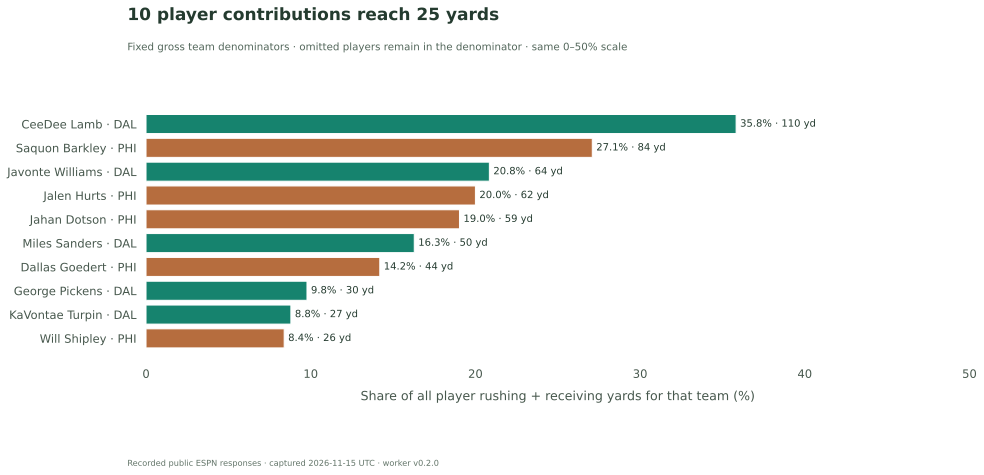

In [14]:
display(yard_audit)
display(selected_players)
prose(
    "Gross scrimmage denominators are "
    + ", ".join(
        f"**{r.team_abbreviation} {int(r.gross_scrimmage_yards)} yards** (net offense {int(r.net_offense_yards)}, sack losses {int(r.sack_yards_lost)})"
        for r in yard_audit.itertuples()
    )
    + f". At **{MIN_SCRIMMAGE_YARDS} yards**, **{len(selected_players)} positive-contribution players** are shown. Their shares use the unchanged full-team gross denominator, so the displayed bars need not sum to 100%. No contribution share is an estimate of player value."
)
fig, ax = plt.subplots(figsize=(13, 7))
if len(selected_players):
    labels = [f"{r.athlete_name} · {r.team_abbreviation}" for r in selected_players.itertuples()]
    colors = ["#16836e" if r.team_abbreviation == "DAL" else "#b66d3e" for r in selected_players.itertuples()]
    bars = ax.barh(labels, selected_players.pct_gross_scrimmage, color=colors)
    ax.bar_label(
        bars,
        labels=[
            f"{r.pct_gross_scrimmage:.1f}% · {int(r.scrimmage_yards)} yd"
            for r in selected_players.itertuples()
        ],
        padding=4,
        fontsize=10,
    )
    ax.invert_yaxis()
else:
    ax.text(
        0.5,
        0.5,
        "No positive-contribution player reaches this threshold",
        transform=ax.transAxes,
        ha="center",
        va="center",
    )
    ax.set_yticks([])
ax.set_xlim(0, 50)
ax.set_xlabel("Share of all player rushing + receiving yards for that team (%)")
finish(
    fig,
    title=f"{len(selected_players)} player contributions reach {MIN_SCRIMMAGE_YARDS} yards",
    subtitle="Fixed gross team denominators · omitted players remain in the denominator · same 0–50% scale",
    source=SOURCE,
    name=f"game-contributions-{MIN_SCRIMMAGE_YARDS}",
)

In [15]:
%%sql checks <<
SELECT 'Single resolved event' AS check_name,count(*)=1 AND bool_and(game_id='401772510') AS passed FROM resolved_game
UNION ALL SELECT 'Week game IDs unique',count(*)=count(DISTINCT game_id) FROM week_games
UNION ALL SELECT 'Club game IDs unique',count(*)=count(DISTINCT game_id) FROM club_games
UNION ALL SELECT 'Directory IDs unique',count(*)=32 AND count(*)=count(DISTINCT team_id) FROM team_directory
UNION ALL SELECT 'Scores agree across three collections',bool_and(home_score=club_home_score AND home_score=summary_home_score AND away_score=club_away_score AND away_score=summary_away_score) FROM resolved_game
UNION ALL SELECT 'Four-quarter summary adds to scores',bool_and(period=4 AND home_q1+home_q2+home_q3+home_q4=home_score AND away_q1+away_q2+away_q3+away_q4=away_score) FROM summary
UNION ALL SELECT 'Event IDs unique',count(*)=count(DISTINCT play_id) FROM event_rows
UNION ALL SELECT 'Scoring play IDs unique',count(*)=count(DISTINCT play_id) FROM score_rows
UNION ALL SELECT 'Scoring records match their play and drive',count(*)=(SELECT count(*) FROM score_rows) AND bool_and(p.play_id IS NOT NULL AND p.scoring_play AND p.away_score=s.away_score AND p.home_score=s.home_score AND d.team_id=s.team_id AND d.is_score) FROM score_rows s LEFT JOIN event_rows p USING(play_id) LEFT JOIN drive_rows d ON d.drive_number=p.drive_number
UNION ALL SELECT 'All flagged scoring events accounted',count(*)=(SELECT count(*) FROM score_rows) FROM event_rows WHERE scoring_play
UNION ALL SELECT 'Final event score matches summary',bool_and(e.away_score=s.away_score AND e.home_score=s.home_score) FROM (SELECT * FROM event_rows ORDER BY sequence DESC LIMIT 1)e CROSS JOIN summary s
UNION ALL SELECT 'Drive counts and possession duration agree',bool_and(d.drives=t.total_drives AND d.total_seconds=t.possession_seconds) FROM team_box t JOIN (SELECT team_id,count(*)drives,sum(duration_seconds) AS total_seconds FROM drive_rows GROUP BY team_id)d USING(team_id)
UNION ALL SELECT 'Player box IDs unique',count(*)=count(DISTINCT athlete_id) FROM player_box
UNION ALL SELECT 'Player passing and receiving agree',bool_and(p.pass_yards=p.receiving_yards) FROM (SELECT team_id,sum(coalesce(pass_yards,0))pass_yards,sum(coalesce(receiving_yards,0))receiving_yards FROM player_box GROUP BY team_id)p
UNION ALL SELECT 'Gross yards equal net plus sacks',bool_and(g.gross_scrimmage_yards=t.total_yards+t.sack_yards_lost AND t.total_yards=t.passing_yards+t.rushing_yards) FROM gross_by_team g JOIN team_box t USING(team_id)
UNION ALL SELECT 'All-player gross shares sum to100',bool_and(abs(p.pct-100)<1e-9) FROM (SELECT p.team_id,sum(100.0*p.scrimmage_yards/g.gross_scrimmage_yards)pct FROM player_yards p JOIN gross_by_team g USING(team_id) GROUP BY p.team_id)p
UNION ALL SELECT 'Display threshold applied without renormalization',coalesce(bool_and(scrimmage_yards>0 AND scrimmage_yards>={{MIN_SCRIMMAGE_YARDS}} AND abs(pct_gross_scrimmage-100.0*scrimmage_yards/gross_scrimmage_yards)<1e-9),true) FROM player_display;

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-04.json").write_text(
    json.dumps(
        {
            "parameters": {"DATA_MODE": DATA_MODE, "MIN_SCRIMMAGE_YARDS": MIN_SCRIMMAGE_YARDS},
            "source_scope": source_scope.to_dict("records"),
            "timeline": timeline.to_dict("records"),
            "drive_audit": drive_audit.to_dict("records"),
            "yard_audit": yard_audit.to_dict("records"),
            "selected_players": selected_players.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,Single resolved event,True
1,Week game IDs unique,True
2,Club game IDs unique,True
3,Directory IDs unique,True
4,Scores agree across three collections,True
5,Four-quarter summary adds to scores,True
6,Event IDs unique,True
7,Scoring play IDs unique,True
8,Scoring records match their play and drive,True
9,All flagged scoring events accounted,True


**All 17 SQL checks passed.** Exactly 4 recorded responses requested once each; no unexpected requests.

10707

### Change one thing

Change only `MIN_SCRIMMAGE_YARDS` from **25 to 75**. Fewer displayed players should remain, while every player’s count and gross-denominator share stays fixed. The scoring figure and all source/drive/yardage audits must remain identical. Try **150** for a clean empty display; the full-team denominators still exist. Restore **25**. This is display sensitivity for one game, not a player-quality threshold.

In [17]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nfl](https://github.com/Query-farm/vgi-nfl)